<a href="https://colab.research.google.com/github/gulozturkk/temel_makine_ogrenmesi/blob/main/makine_ogrenmesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as tf_sns
import tensorflow as tf
from sklearn.metrics import classification_report , confusion_matrix
from tensorflow.keras import layers , models

mnist = tf.keras.datasets.mnist
(X_train_raw , y_train) , (X_test_raw , y_test) = mnist.load_data()

print(f"Eğitim seti örnek sayısı: {X_train_raw.shape[0]}")
print(f"Test seti örnek sayısı: {X_test_raw.shape[0]}")
print(f"Görsel boyutları: {X_train_raw.shape[1]} x {X_train_raw.shape[2]} piksel")



Eğitim seti örnek sayısı: 60000
Test seti örnek sayısı: 10000
Görsel boyutları: 28 x 28 piksel


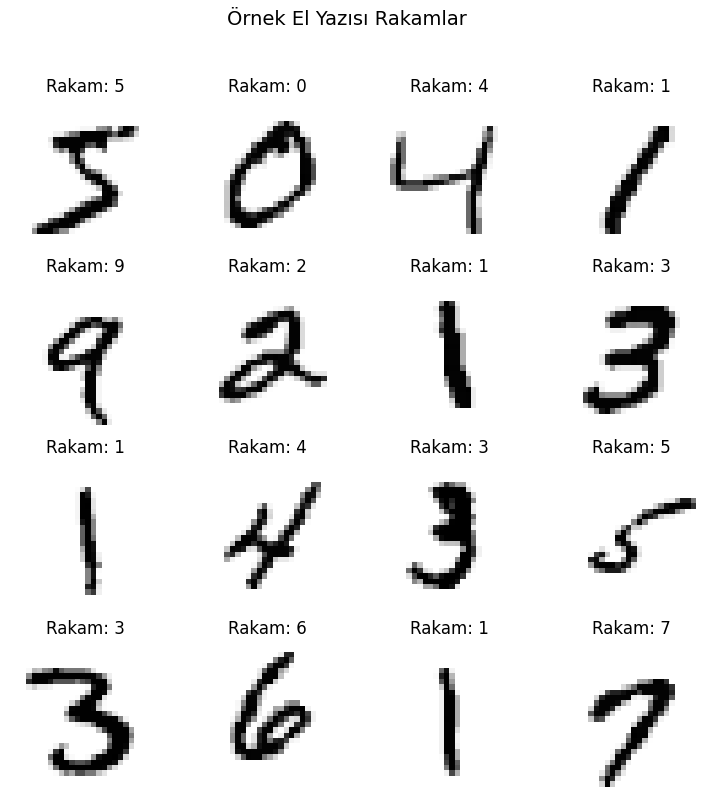

In [ ]:
plt.figure(figsize=(9,9))
for i in range(16):
  plt.subplot(4,4,i+1)
  plt.imshow(X_train_raw[i],cmap="Grays")
  plt.title(f"Rakam: {y_train[i]}")
  plt.axis("off")
plt.suptitle("Örnek El Yazısı Rakamlar",fontsize=14)
plt.show()

In [ ]:
#normalizasyon
X_train = X_train_raw / 255.0
X_test = X_test_raw / 255.0

# CNN mimarisi için kanal boyutunun eklenmesi
X_train = X_train[..., tf.newaxis]
X_test = X_test[..., tf.newaxis]

print("Yeni Eğitim verisi şekli: ",X_train.shape)


Yeni Eğitim verisi şekli:  (60000, 28, 28, 1)


In [ ]:
#evrişimli katmanlar ve pooling katmanları
model = models.Sequential([
    layers.Conv2D(32,(3,3),activation="relu",input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"), #gizli katman
    layers.Dropout(0.3), #overfittingi önlemek için
    layers.Dense(10,activation="softmax") #çıktı katmanı
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 56ms/step - accuracy: 0.9329 - loss: 0.2206 - val_accuracy: 0.9825 - val_loss: 0.0595
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 60ms/step - accuracy: 0.9791 - loss: 0.0676 - val_accuracy: 0.9847 - val_loss: 0.0490
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9851 - loss: 0.0492 - val_accuracy: 0.9881 - val_loss: 0.0402
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 57ms/step - accuracy: 0.9883 - loss: 0.0383 - val_accuracy: 0.9898 - val_loss: 0.0370
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9901 - loss: 0.0309 - val_accuracy: 0.9902 - val_loss: 0.0368
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.9915 - loss: 0.0264 - val_accuracy: 0.9894 - val_loss: 0.0387
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 58ms/step - accuracy: 0.9931 - loss: 0.0221 - val_accuracy: 0.9881 - val_loss: 0.0409
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 56ms/step - accuracy: 0.9935 - loss: 0.0185 - 

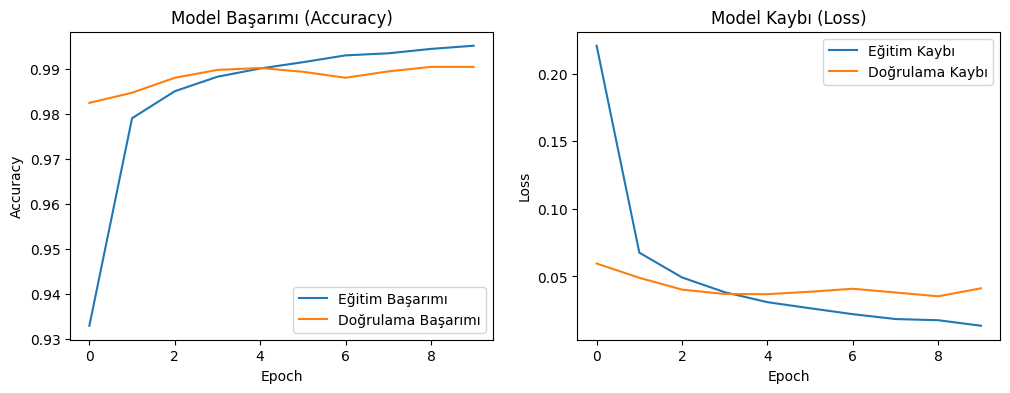

In [ ]:
#model eğitimi
#epoch = 10 , batch size = 64

ep = 10
basize = 64
history = model.fit(
    X_train,
    y_train,
    epochs = ep,
    batch_size = basize,
    validation_split = 0.2 #eğitim verisinin 20 si doğrulama içinm ayrıldı

)
test_loss , test_acc = model.evaluate(X_test,y_test,verbose=2)
print(f"Test doğruluğu: {test_acc:.4f}")
print(f"Test kaybı: {test_loss:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Eğitim Başarımı")
plt.plot(history.history["val_accuracy"], label="Doğrulama Başarımı")
plt.title("Model Başarımı (Accuracy)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Eğitim Kaybı")
plt.plot(history.history["val_loss"], label="Doğrulama Kaybı")
plt.title("Model Kaybı (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


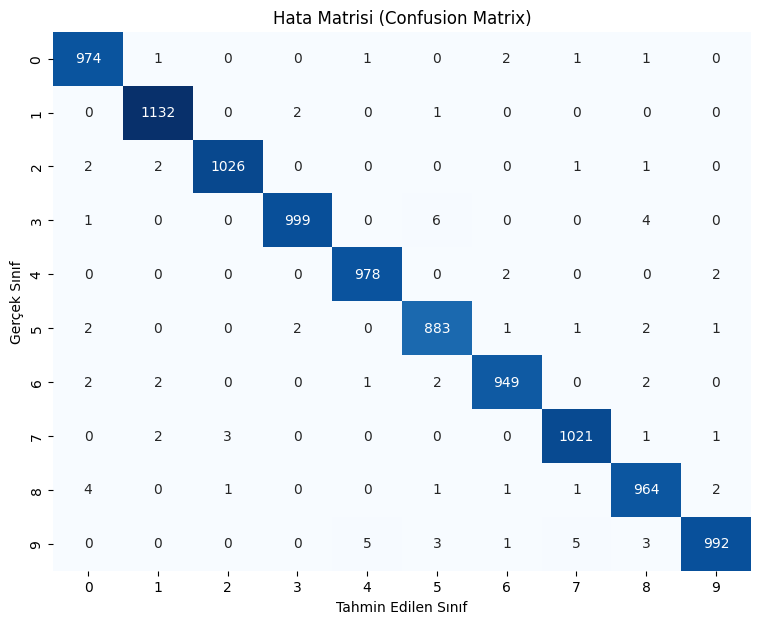


--- Sınıflandırma Raporu ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      1.00      1032
           3       1.00      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [ ]:
#hata analizi ve confusion matrix
y_pred_probs = model.predict(X_test)
y_pred =np.argmax(y_pred_probs,axis=1)
conf_matrix = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(9, 7))
tf_sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Hata Matrisi (Confusion Matrix)")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.show()

print("Sınıflandırma Raporu")
print(classification_report(y_test, y_pred))